<a href="https://colab.research.google.com/github/KubiProjekty/orangepi-iot-telemetry-analytics/blob/main/analiza/03_machine_learning_predykcja.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Liczba lotów w analizie: 368 | Skuteczność (Accuracy) modelu: 90.5%

=== RAPORT KLASYFIKACJI ===
                             precision    recall  f1-score   support

           Tranzyt (>=9 km)       0.96      0.90      0.93        49
Wznoszenie/Zniżanie (<9 km)       0.82      0.92      0.87        25

                   accuracy                           0.91        74
                  macro avg       0.89      0.91      0.90        74
               weighted avg       0.91      0.91      0.91        74



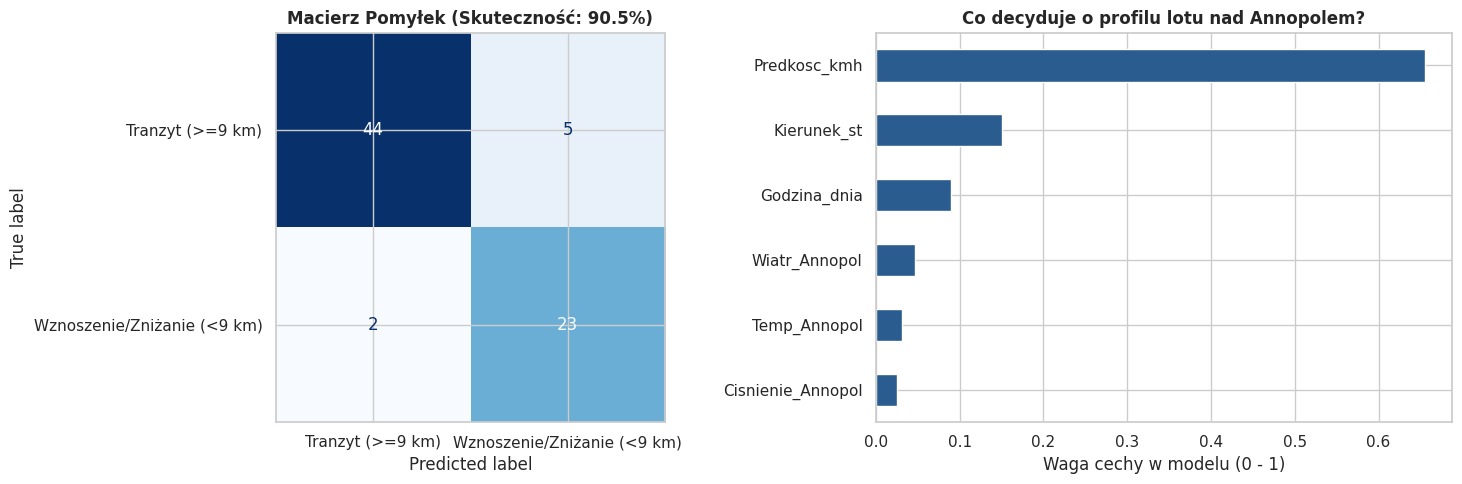

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# 1. Pobranie danych bezpośrednio z Twojego repozytorium na GitHubie
host = "raw" + "." + "githubusercontent" + "." + "com"
user = "KubiProjekty"
repo = "orangepi-iot-telemetry-analytics"
base_url = f"https://{host}/{user}/{repo}/main/dane/"

df_loty = pd.read_csv(base_url + "historia_lotow.csv")
df_pogoda = pd.read_csv(base_url + "historia_pogody.csv")

# Pobieramy automatycznie nazwę ostatniej kolumny z kursem/kierunkiem lotu
kolumna_kierunek = df_loty.columns[-1]

df_loty['Data'] = pd.to_datetime(df_loty['Data'])
df_loty['Godzina_klucz'] = df_loty['Data'].dt.floor('h')
df_loty['Godzina_dnia'] = df_loty['Data'].dt.hour
df_loty = df_loty[df_loty['Predkosc_kmh'] <= 1200].copy()

# 2. Pogoda z Annopola (uśredniona godzinowo)
df_pogoda['Data'] = pd.to_datetime(df_pogoda['Data'])
df_pogoda['Godzina_klucz'] = df_pogoda['Data'].dt.floor('h')

pogoda_annopol_h = df_pogoda[df_pogoda['Miasto'].str.contains('Annopol', case=False, na=False)].groupby('Godzina_klucz').agg(
    Temp_Annopol=('Temp_C', 'mean'),
    Wiatr_Annopol=('Wiatr_kmh', 'mean'),
    Cisnienie_Annopol=('Cisnienie_hPa', 'mean')
).reset_index()

df_loty_ml = pd.merge(df_loty, pogoda_annopol_h, on='Godzina_klucz', how='inner').dropna()

# 3. Definiujemy cel klasyfikacji (Target):
# Czy samolot leci na pułapie tranzytowym (>= 9000 m), czy wykonuje operację wznoszenia/zniżania (< 9000 m)?
df_loty_ml['Typ_Operacji'] = np.where(df_loty_ml['Wysokosc_m'] >= 9000, 'Tranzyt (>=9 km)', 'Wznoszenie/Zniżanie (<9 km)')

# Cechy wejściowe (bez samej wysokości, żeby model uczył się z fizyki lotu i pogody!)
cechy_loty = ['Predkosc_kmh', kolumna_kierunek, 'Godzina_dnia', 'Temp_Annopol', 'Wiatr_Annopol', 'Cisnienie_Annopol']
X_l = df_loty_ml[cechy_loty]
y_l = df_loty_ml['Typ_Operacji']

# 4. Podział 80/20 i trening klasyfikatora Random Forest
X_tr, X_te, y_tr, y_te = train_test_split(X_l, y_l, test_size=0.2, random_state=42)
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_tr, y_tr)

y_pr = clf.predict(X_te)
acc = accuracy_score(y_te, y_pr)

print(f"Liczba lotów w analizie: {len(df_loty_ml)} | Skuteczność (Accuracy) modelu: {acc*100:.1f}%\n")
print("=== RAPORT KLASYFIKACJI ===")
print(classification_report(y_te, y_pr))

# 5. Macierz pomyłek (Confusion Matrix) i Ważność cech
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ConfusionMatrixDisplay.from_estimator(clf, X_te, y_te, ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Macierz Pomyłek (Skuteczność: {acc*100:.1f}%)', fontsize=12, fontweight='bold')

waznosc_l = pd.Series(clf.feature_importances_, index=cechy_loty).sort_values(ascending=True)
waznosc_l.plot(kind='barh', ax=axes[1], color='#2b5c8f')
axes[1].set_title('Co decyduje o profilu lotu nad Annopolem?', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Waga cechy w modelu (0 - 1)')

plt.tight_layout()
plt.show()
